        # Which forecast goes to the plan, how many packer shifts a week, and what does a miss cost?

        **Week 4, Friday, chapter 3 of 3.** **The ticket.** Flipkart, the Lucknow fulfilment centre, festive packer headcount. The centre
has 104 weeks of outbound shipments, the weeks beginning Monday 30 September 2024 to Monday 21
September 2026. Diwali fell on Thursday 31 October 2024 and Monday 20 October 2025, and falls on
Sunday 8 November 2026. A packer packs about 120 shipments a shift. The planner must book packer
shifts for the eight festive weeks beginning 12 October to 30 November 2026. A vendor's demand
model promises the festive window 22 percent above last year's; finance's rule is last year's
window plus 4 percent, eighteen points apart. An idle packer-shift costs Rs 650 (assumed, Rs 500 to
800) and a late shipment Rs 25 (assumed, Rs 15 to 40). Illustrative case: the company is real, the situation and the data are synthetic, built for this class.

        Chapter 2 scored every rule on thirteen hidden summer weeks: festival-aligned and finance's
        rule tied at 6,615 a week, the house bot scored 9,831, the vendor 16,400. None of those
        weeks held a festival, so the hold-out could not test the one thing the plan depends on.

        **Who needs the answer.** The FC planner, who books the shifts, and the regional operations
        head, who answers for late parcels in the festival's busiest weeks. A plan that puts the
        peak in the wrong week pays for idle packers and late shipments in the same month.

        **The questions on the way.** How did each rule do on 2025's festival? Which week does each
        forecast put this year's peak in? How do the four forecasts compare with last year's two
        windows? How far above the forecast should the plan sit? How many shifts a week? What would
        the other plans cost?

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

weekly = pd.read_csv("../data/C2_W04_D05_weekly_shipments_STUDENT.csv", parse_dates=["week_start"])
vendor = pd.read_csv("../data/C2_W04_D05_vendor_forecast_STUDENT.csv", parse_dates=["week_start"])
y = weekly.set_index("week_start").shipments
v = vendor.set_index("week_start").vendor_shipments
diwali = {2024: pd.Timestamp("2024-10-28"), 2025: pd.Timestamp("2025-10-20"), 2026: pd.Timestamp("2026-11-02")}

def aligned_source(d):
    """The week festival-aligned copies: the same distance from last year's Diwali near the festival."""
    near = min(diwali.values(), key=lambda w: abs((d - w).days))
    gap = (d - near).days // 7
    if -5 <= gap <= 4 and near.year - 1 in diwali:
        return diwali[near.year - 1] + pd.Timedelta(weeks=gap)
    return d - pd.Timedelta(weeks=52)

print(aligned_source(pd.Timestamp("2026-10-19")).date(), "is the source for the week of 19 Oct 2026")
check("the week of 19 Oct 2026 copies 6 Oct 2025", aligned_source(pd.Timestamp("2026-10-19")) == pd.Timestamp("2025-10-06"))

2025-10-06 is the source for the week of 19 Oct 2026
PASS the week of 19 Oct 2026 copies 6 Oct 2025


## How did each rule do on 2025's festival?

The only festival the data can test the rules on is 2025's. Stand in the week of 22
September 2025 and forecast the eight weeks from 29 September to 17 November 2025.

**Predict before you run.** By how many weeks does the house bot miss 2025's peak?

a) none: same week last year knows the season
b) one week late
c) one week early
d) two weeks late

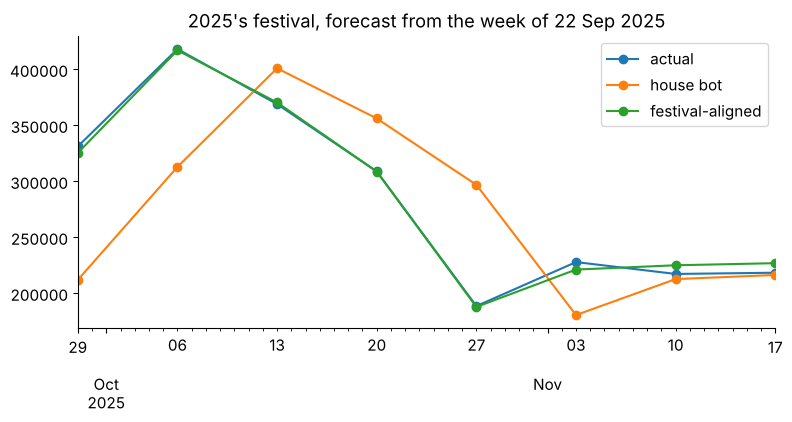

house bot         MAE  58,250   cost Rs 79.8 lakh
festival-aligned  MAE   4,034   cost Rs 4.6 lakh
PASS the bot's peak is 13 Oct 2025, a week late
PASS festival-aligned peaks on 6 Oct 2025 with the actual


In [2]:
weeks25 = pd.date_range("2025-09-29", periods=8, freq="7D")
back = pd.DataFrame({
    "actual": y.loc[weeks25],
    "house bot": [y[d - pd.Timedelta(weeks=52)] for d in weeks25],
    "festival-aligned": [round(y[aligned_source(d)] * 1.04) for d in weeks25],
}, index=weeks25)
back.plot(marker="o", title="2025's festival, forecast from the week of 22 Sep 2025")
plt.show()
for rule in ["house bot", "festival-aligned"]:
    over = (back[rule] - back.actual).clip(lower=0).sum()
    under = (back.actual - back[rule]).clip(lower=0).sum()
    print(f"{rule:17s} MAE {(back[rule] - back.actual).abs().mean():>7,.0f}   cost Rs {(over * 650 / 120 + under * 25) / 1e5:.1f} lakh")
check("the bot's peak is 13 Oct 2025, a week late", back["house bot"].idxmax() == pd.Timestamp("2025-10-13"))
check("festival-aligned peaks on 6 Oct 2025 with the actual", back["festival-aligned"].idxmax() == back.actual.idxmax())

**What happened.** The answer is b. The house bot put 2024's peak on 13 October 2025, a
week late: MAE 58,250 and Rs 79.8 lakh of misses, mostly late shipments in the week the
real peak came. Festival-aligned missed by 4,034 a week and Rs 4.6 lakh. One festival is a
thin test, so the plan treats this as evidence about placement, never as a precise error.

## Which week does each forecast put this year's peak in?

Diwali 2026 falls on Sunday 8 November, so its week begins 2 November and the peak should
come two weeks before, on the week of 19 October.

**Predict before you run.** Which week does the house bot's copy of 2025 make the busiest
week of the festive season?

a) 5 October 2026
b) 19 October 2026
c) 26 October 2026
d) 2 November 2026

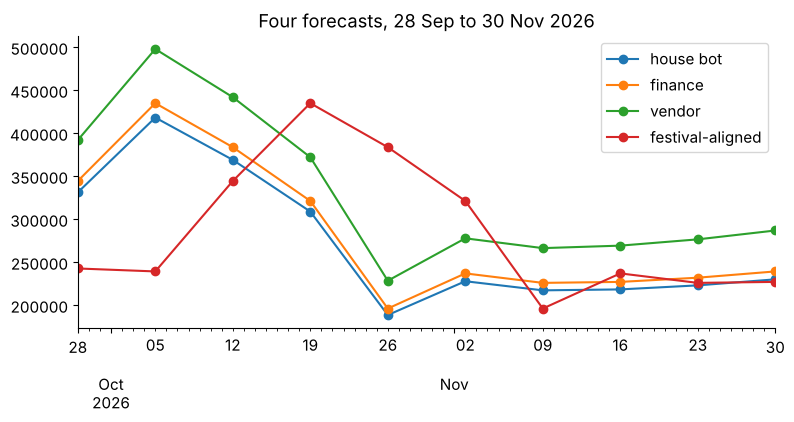

house bot           2026-10-05
finance             2026-10-05
vendor              2026-10-05
festival-aligned    2026-10-19
PASS the bot's busiest week is 5 Oct 2026
PASS festival-aligned's busiest week is 19 Oct 2026


In [3]:
weeks26 = pd.date_range("2026-09-28", periods=10, freq="7D")
ahead = pd.DataFrame({
    "house bot": [y[d - pd.Timedelta(weeks=52)] for d in weeks26],
    "finance": [round(y[d - pd.Timedelta(weeks=52)] * 1.04) for d in weeks26],
    "vendor": v.loc[weeks26].values,
    "festival-aligned": [round(y[aligned_source(d)] * 1.04) for d in weeks26],
}, index=weeks26)
ahead.plot(marker="o", title="Four forecasts, 28 Sep to 30 Nov 2026")
plt.show()
print(ahead.idxmax().dt.date.to_string())
check("the bot's busiest week is 5 Oct 2026", ahead["house bot"].idxmax() == pd.Timestamp("2026-10-05"))
check("festival-aligned's busiest week is 19 Oct 2026", ahead["festival-aligned"].idxmax() == pd.Timestamp("2026-10-19"))

**What happened.** The answer is a. The house bot, finance's rule and the vendor all make 5
October 2026 the busiest week, because each copies 2025's calendar weeks; festival-aligned
puts it on 19 October, two weeks before Diwali's week. The vendor's model never knew the
festival moved.

## How do the four forecasts compare with last year's window?

"Last year's window" has two readings. The same calendar weeks, 13 October to 1 December
2025, hold only the tail of 2025's festival. The same weeks counted from Diwali, 29
September to 17 November 2025, hold all of it.

In [4]:
window = weeks26[2:]                                    # 12 Oct to 30 Nov 2026
calendar_2025 = y.loc[window - pd.Timedelta(weeks=52)].sum()
festival_2025 = y.loc[[aligned_source(d) for d in window]].sum()
totals = ahead.loc[window].sum()
compare = pd.DataFrame({"eight weeks": totals.map("{:,}".format),
                        "vs same calendar weeks": (totals / calendar_2025 - 1).map("{:+.1%}".format),
                        "vs same weeks from Diwali": (totals / festival_2025 - 1).map("{:+.1%}".format)})
print(f"2025, same calendar weeks: {calendar_2025:,}   2025, same weeks from Diwali: {festival_2025:,}")
print(compare.to_string())
check("finance is plus 4 percent on the calendar window", round(totals["finance"] / calendar_2025 - 1, 3) == 0.04)
check("the vendor is plus 22 percent on the calendar window", round(totals["vendor"] / calendar_2025 - 1, 3) == 0.22)
check("finance sits below festival-aligned", totals["finance"] < totals["festival-aligned"])

2025, same calendar weeks: 1,983,300   2025, same weeks from Diwali: 2,279,500
                 eight weeks vs same calendar weeks vs same weeks from Diwali
house bot          1,983,300                  +0.0%                    -13.0%
finance            2,062,632                  +4.0%                     -9.5%
vendor             2,419,500                 +22.0%                     +6.1%
festival-aligned   2,370,680                 +19.5%                     +4.0%
PASS finance is plus 4 percent on the calendar window
PASS the vendor is plus 22 percent on the calendar window
PASS finance sits below festival-aligned


**What happened.** Against the calendar weeks, festival-aligned reads 19.5 percent above
last year, close to the vendor's 22.0, because 2026's peak weeks fall inside the window and
2025's fell before it. Against the weeks counted from Diwali it reads 4.0 percent. Finance's
plus 4 is plus 4 only on the calendar window: it is 9.5 percent below last year's festival
weeks and 308,048 shipments below festival-aligned, and short is the costly side. The
vendor's total sits 2.1 percent above festival-aligned, with its busiest week on 5 October.

## How far above the forecast should the plan sit?

A shipment planned and not shipped costs Rs 650 / 120 = Rs 5.42 of idle shift; a shipment
short costs Rs 25. The plan should cover demand in the share of weeks that balances the two:
25 / (25 + 5.42), about 0.82. Read that share off the forecast's own misses on the hidden
weeks of chapter 2.

plan share 0.82: demand beat the forecast by more than 2.6% in 18% of the hidden weeks


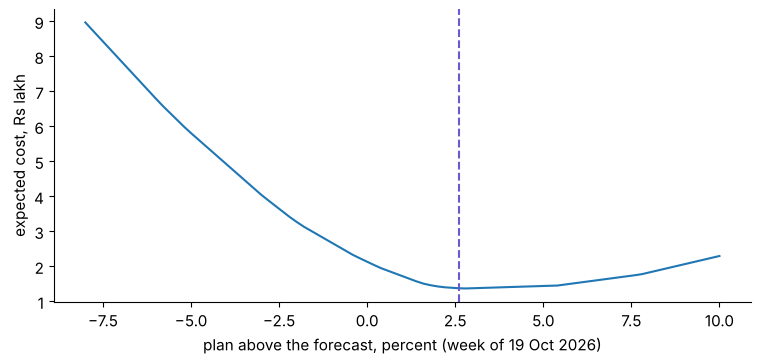

PASS the plan share is about 0.82
PASS the cheapest level sits above the forecast


In [5]:
hold = y.iloc[91:]
fa_hold = (y.shift(52).loc[hold.index] * 1.04).round()
misses = (hold - fa_hold) / fa_hold                     # positive: demand above the forecast
q = 25 / (25 + 650 / 120)
cushion = round(misses.quantile(q), 3)                  # rounded to a tenth of a percent
print(f"plan share {q:.2f}: demand beat the forecast by more than {cushion:.1%} in {1 - q:.0%} of the hidden weeks")
grid = [i / 1000 for i in range(-80, 101, 2)]
base = ahead.loc["2026-10-19", "festival-aligned"]
cost = [sum(650 / 120 * max(0, base * (1 + g) - base * (1 + m)) + 25 * max(0, base * (1 + m) - base * (1 + g))
            for m in misses) / 13 / 1e5 for g in grid]
plt.plot([g * 100 for g in grid], cost)
plt.axvline(cushion * 100, ls="--", color="slateblue")
plt.xlabel("plan above the forecast, percent (week of 19 Oct 2026)")
plt.ylabel("expected cost, Rs lakh")
plt.show()
check("the plan share is about 0.82", round(q, 2) == 0.82)
check("the cheapest level sits above the forecast", grid[cost.index(min(cost))] > 0)

## How many packer shifts does each week need?

The plan raises each week of the festival-aligned forecast by the 2.6 percent cushion, then
divides by 120 shipments a shift and rounds up.

            forecast    plan  packer shifts
2026-10-12    344448  353404           2946
2026-10-19    434928  446236           3719
2026-10-26    383760  393738           3282
2026-11-02    321256  329609           2747
2026-11-09    196144  201244           1678
2026-11-16    237016  243178           2027
2026-11-23    225992  231868           1933
2026-11-30    227136  233042           1943
total: 20,275 packer shifts over eight weeks


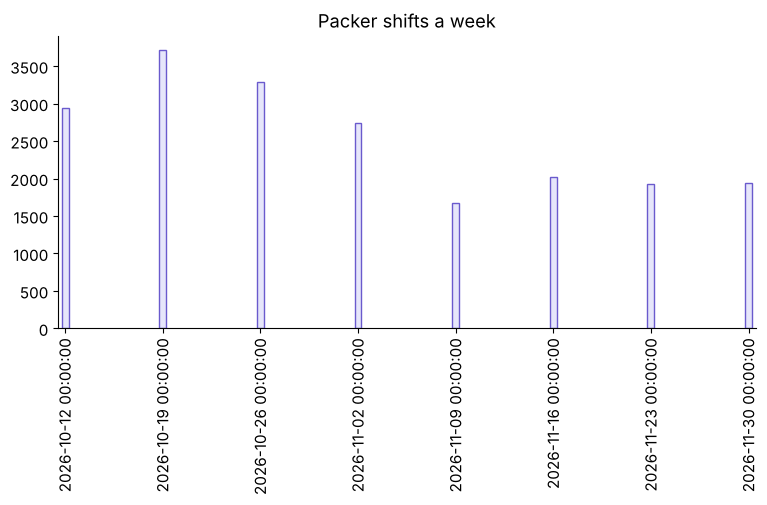

PASS the busiest week of the plan is 19 Oct 2026


In [6]:
plan = (ahead.loc[window, "festival-aligned"] * (1 + cushion)).round()
shifts = (plan / 120).apply(math.ceil)
staffing = pd.DataFrame({"forecast": ahead.loc[window, "festival-aligned"], "plan": plan.astype(int),
                         "packer shifts": shifts})
print(staffing.to_string())
print(f"total: {shifts.sum():,} packer shifts over eight weeks")
staffing["packer shifts"].plot.bar(color="lavender", edgecolor="slateblue", title="Packer shifts a week")
plt.show()
check("the busiest week of the plan is 19 Oct 2026", staffing["packer shifts"].idxmax() == pd.Timestamp("2026-10-19"))

## What would the other plans cost if demand follows the festival-aligned forecast?

A scenario, never a measurement: price each plan against festival-aligned's weeks, Rs 5.42
for every shipment of spare capacity and Rs 25 for every shipment short.

In [7]:
expected = ahead.loc[window, "festival-aligned"]
plans = ahead.loc[window, ["house bot", "finance", "vendor"]].assign(plan=plan)
over = plans.sub(expected, axis=0).clip(lower=0).sum()
under = plans.rsub(expected, axis=0).clip(lower=0).sum()
print(((over * 650 / 120 + under * 25) / 1e5).round(1).to_string())
check("the plan costs least in this scenario",
      ((over * 650 / 120 + under * 25)).idxmin() == "plan")

house bot    111.6
finance      103.6
vendor        82.2
plan           3.3
PASS the plan costs least in this scenario


**What happened.** If demand follows festival-aligned, the house bot's weeks cost Rs 111.6
lakh, finance's Rs 103.6 lakh and the vendor's Rs 82.2 lakh, mostly late shipments in the
weeks of 19 October to 2 November. The plan's cushion costs Rs 3.3 lakh of spare shifts if
demand lands exactly on the forecast, which is what the insurance costs.

## What can two years of weeks not tell us?

- **The festival moves, and the sale moves with it.** Checked on one festival only: the 2025
  back-test.
- **One spike a year is two spikes in two years.** No check inside the data closes it.
- **The hold-out holds no festive week,** so its 6,615 is an ordinary-week error; the 2025
  festival gave 4,034 on one festival.
- **Capacity clips the peak.** Overtime shifts reached 1,638 in the week of 6 October 2025
  against 5 in an ordinary November week, so peak demand may have been higher than shipped.
- **The 4 percent growth** is two years' evidence; a third year could move it.
- **A vendor model with no Lucknow festival in its forecast record** is an assumption, like
  a forecast with no history behind it.

## The same method at an AI company: how much inference capacity does a launch need?

A product launch is the festival: a known date, a spike, little history. Hide as many days
as the plan covers, score in requests a minute, compare with last launch's shape, and set
capacity above the median because a timeout costs more than an idle server.

## What did chapter 3 answer?

- **2025's festival:** the house bot landed the peak a week late (Rs 79.8 lakh of misses);
  festival-aligned missed by Rs 4.6 lakh.
- **This year's peak:** the house bot, finance and the vendor put it on 5 October 2026;
  festival-aligned on 19 October.
- **Last year's windows:** festival-aligned is 19.5 percent above the calendar weeks and 4.0
  percent above the weeks from Diwali; finance is 9.5 percent below the festival weeks.
- **How far above:** the 0.82 share, a 2.6 percent cushion.
- **Shifts:** 20,275 over eight weeks, 3,719 in the week of 19 October.
- **The others' cost:** Rs 82.2 to 111.6 lakh if demand follows festival-aligned; the
  cushion Rs 3.3 lakh.